In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [44]:
df = pd.read_csv('telecom_churn.csv')

In [45]:
df.sample(5)

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
2182,0,170,1,1,3.51,0,178.1,130,86.1,12.14,13.0
3007,0,204,1,0,0.00,3,205.2,145,49.0,7.74,14.1
2581,1,123,1,0,0.00,4,123.2,104,38.0,9.50,12.9
2540,0,90,1,1,3.48,1,71.2,82,62.8,9.08,12.9
3036,0,112,1,0,0.00,3,214.8,112,55.0,10.49,9.4


In [46]:
df


,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,0,128,1,1,2.70,1,265.1,110,89.0,9.87,10.0
1,0,107,1,1,3.70,1,161.6,123,82.0,9.78,13.7
2,0,137,1,0,0.00,0,243.4,114,52.0,6.06,12.2
3,0,84,0,0,0.00,2,299.4,71,57.0,3.10,6.6
4,0,75,0,0,0.00,3,166.7,113,41.0,7.42,10.1
...,...,...,...,...,...,...,...,...,...,...,...
3328,0,192,1,1,2.67,2,156.2,77,71.7,10.78,9.9
3329,0,68,1,0,0.34,3,231.1,57,56.4,7.67,9.6
3330,0,28,1,0,0.00,2,180.8,109,56.0,14.44,14.1
3331,0,184,0,0,0.00,2,213.8,105,50.0,7.98,5.0


In [47]:
df = df.iloc[:,0:3]

In [48]:
df

,Churn,AccountWeeks,ContractRenewal
0,0,128,1
1,0,107,1
2,0,137,1
3,0,84,0
4,0,75,0
...,...,...,...
3328,0,192,1
3329,0,68,1
3330,0,28,1
3331,0,184,0


<Axes: xlabel='ContractRenewal', ylabel='count'>

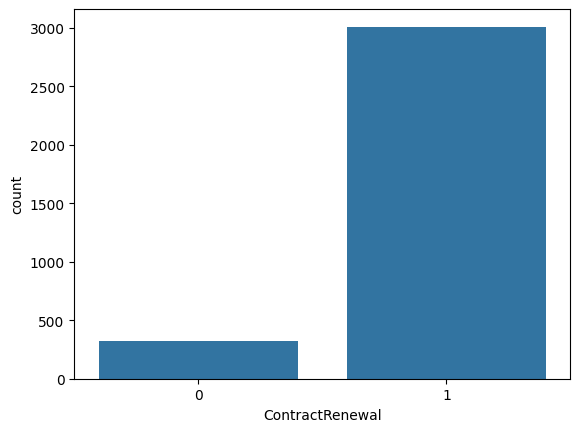

In [49]:
sns.countplot(x='ContractRenewal', data=df)

<Axes: xlabel='Churn', ylabel='count'>

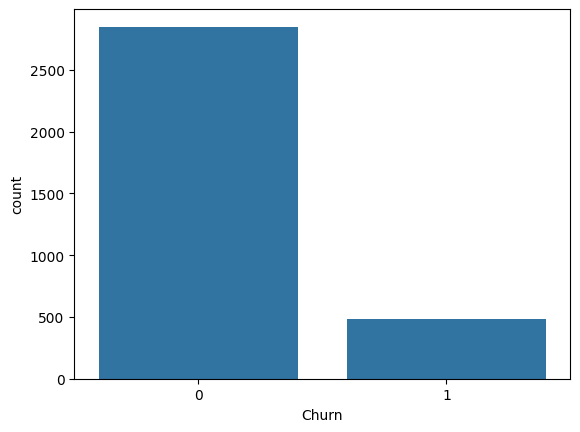

In [50]:
sns.countplot(x='Churn', data=df)

In [51]:
df.sample(5)

,Churn,AccountWeeks,ContractRenewal
1622,0,117,1
362,0,39,1
2834,0,189,1
1127,0,159,1
256,0,108,1


In [52]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(df.drop('ContractRenewal',axis=1),
                                                df['ContractRenewal'],
                                                test_size=0.3,
                                                random_state=0)
X_train.shape, X_test.shape

((2333, 2), (1000, 2))

In [53]:
X_train.sample(5)

,Churn,AccountWeeks
614,0,41
3248,0,93
2045,0,56
2250,0,75
239,0,73


In [54]:
y_train.sample(4)

348     1
1891    1
456     1
792     0
Name: ContractRenewal, dtype: int64

In [55]:
from sklearn.preprocessing import StandardScaler

scaler.fit(X_train)

scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [56]:
scaler.mean_

array([  0.14787827, 100.69395628])

In [57]:
X_train_scaled = pd.DataFrame(X_train_scaled,columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled,columns=X_test.columns)

In [58]:
np.round(X_train.describe(),1)

,Churn,AccountWeeks
count,2333.0,2333.0
mean,0.1,100.7
std,0.4,40.1
min,0.0,1.0
25%,0.0,74.0
50%,0.0,100.0
75%,0.0,127.0
max,1.0,232.0


In [59]:
X_train_scaled

,Churn,AccountWeeks
0,-0.416583,-1.066013
1,-0.416583,-1.240794
2,-0.416583,-0.341921
3,-0.416583,-0.441795
4,2.400483,-0.416827
...,...,...
2328,-0.416583,-1.840044
2329,-0.416583,-0.291983
2330,2.400483,-0.192108
2331,-0.416583,-0.242046


In [60]:
np.round(X_train_scaled.describe(),1)

,Churn,AccountWeeks
count,2333.0,2333.0
mean,0.0,0.0
std,1.0,1.0
min,-0.4,-2.5
25%,-0.4,-0.7
50%,-0.4,-0.0
75%,-0.4,0.7
max,2.4,3.3


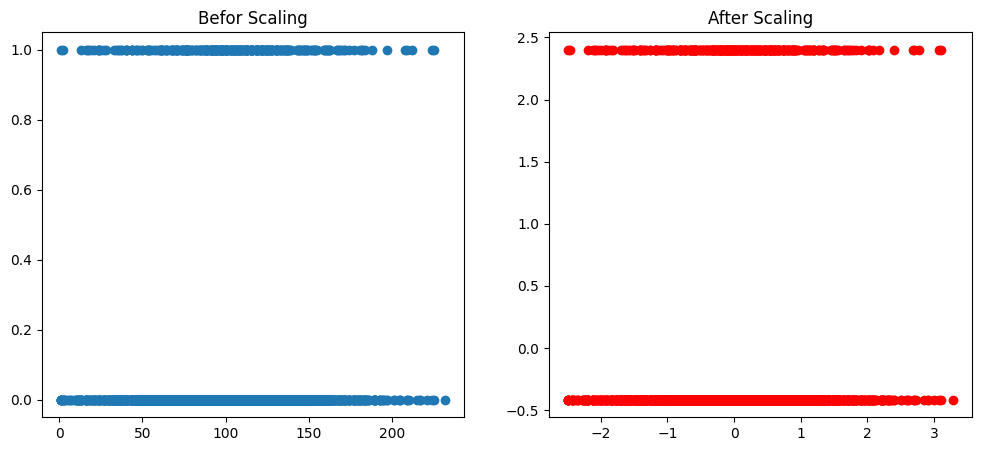

In [61]:
fig, (ax1,ax2) = plt.subplots(ncols=2,figsize=(12,5))

ax1.scatter(X_train['AccountWeeks'],X_train['Churn'])
ax1.set_title("Befor Scaling")
ax2.scatter(X_train_scaled['AccountWeeks'],X_train_scaled['Churn'], color='red')
ax2.set_title('After Scaling')

plt.show()

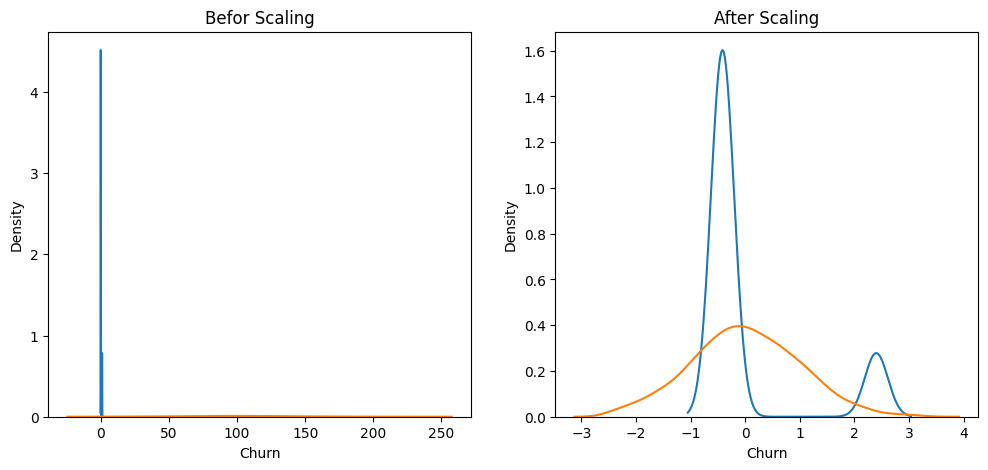

In [64]:
fig,(ax1,ax2) = plt.subplots(ncols=2, figsize=(12,5))

#Befor Scaling
ax1.set_title('Befor Scaling')
sns.kdeplot(X_train['Churn'], ax=ax1)
sns.kdeplot(X_train['AccountWeeks'],ax=ax1)

#After Scaling
ax2.set_title("After Scaling")
sns.kdeplot(X_train_scaled['Churn'], ax=ax2)
sns.kdeplot(X_train_scaled['AccountWeeks'], ax=ax2)
plt.show()

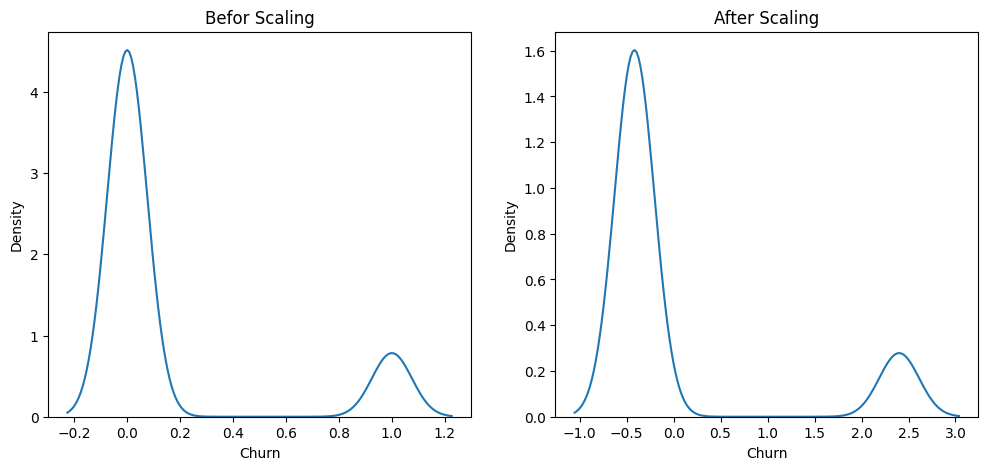

In [65]:
fig,(ax1,ax2) = plt.subplots(ncols=2, figsize=(12,5))

#Befor Scaling
ax1.set_title('Befor Scaling')
sns.kdeplot(X_train['Churn'], ax=ax1)

#After Scaling
ax2.set_title("After Scaling")
sns.kdeplot(X_train_scaled['Churn'], ax=ax2)
plt.show()

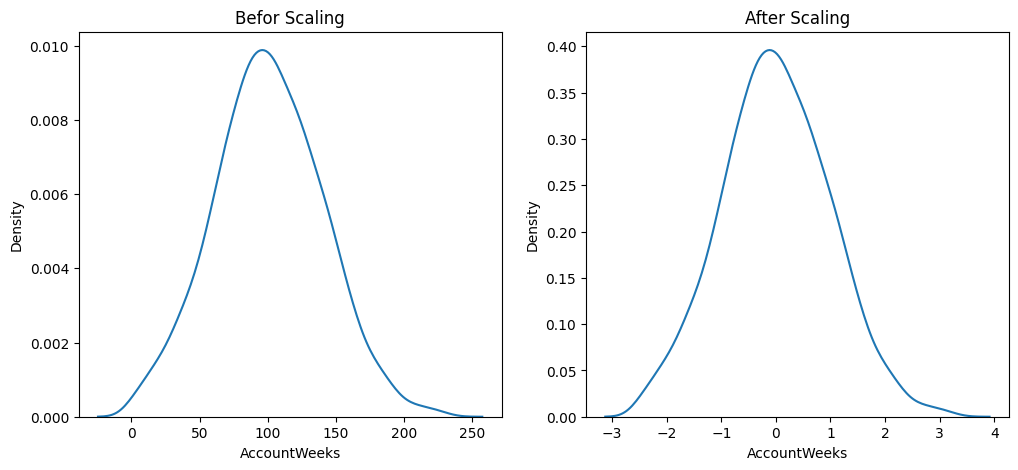

In [66]:
fig,(ax1,ax2) = plt.subplots(ncols=2, figsize=(12,5))

#Befor Scaling
ax1.set_title('Befor Scaling')
sns.kdeplot(X_train['AccountWeeks'],ax=ax1)

#After Scaling
ax2.set_title("After Scaling")
sns.kdeplot(X_train_scaled['AccountWeeks'], ax=ax2)
plt.show()

In [79]:
from sklearn.linear_model import LogisticRegression

In [80]:
lr = LogisticRegression()

In [81]:
lr_scaled = LogisticRegression()

In [82]:
lr.fit(X_train,y_train)
lr_scaled.fit(X_train_scaled,y_train)

LogisticRegression()

In [83]:
y_pred = lr.predict(X_test)
y_pred_scaled = lr_scaled.predict(X_test_scaled)

In [84]:
from sklearn.metrics import accuracy_score


In [85]:
print("Actual",accuracy_score(y_test,y_pred))
print("Scaled",accuracy_score(y_test,y_pred_scaled))

Actual 0.894
Scaled 0.894


In [89]:
from sklearn.tree import DecisionTreeClassifier

In [90]:
dt = DecisionTreeClassifier()

In [92]:
dt_scaled = DecisionTreeClassifier()

In [93]:
dt.fit(X_train,y_train)
dt_scaled.fit(X_train_scaled,y_train)

DecisionTreeClassifier()

In [94]:
y_pred = dt.predict(X_test)
y_pred_scaled = dt_scaled.predict(X_test_scaled)

In [95]:
print('Actual',accuracy_score(y_test,y_pred))
print('Scaled',accuracy_score(y_test,y_pred_scaled))

Actual 0.883
Scaled 0.883


In [96]:
df.describe()

,Churn,AccountWeeks,ContractRenewal
count,3333.000000,3333.000000,3333.000000
mean,0.144914,101.064806,0.903090
std,0.352067,39.822106,0.295879
min,0.000000,1.000000,0.000000
25%,0.000000,74.000000,1.000000
50%,0.000000,101.000000,1.000000
75%,0.000000,127.000000,1.000000
max,1.000000,243.000000,1.000000
